In [1]:
import sys
import os
import pickle
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
file_id = 2

In [4]:
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')

# read
(filename,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_data(path, file_id, with_whisking=True)
timestamps = read_utils.get_timestamps(read_utils.get_filepath(path, file_id))

# clear nan values
# mask = motion_pcs[0].notna().all(axis=1)
mask = continuous_behaviors.notna().all(axis=1)

traces = traces[mask]
motion_pcs[0] = motion_pcs[0][mask]
motion_pcs[1] = motion_pcs[1][mask]
continuous_behaviors = continuous_behaviors[mask]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces.columns, traces.columns == ''))
])

# preprocess
classes = pd.DataFrame(
	continuous_behaviors[['running_speed']].values > np.quantile(continuous_behaviors[['running_speed']].values, 0.05),
	columns=['run']
)

In [5]:
print(traces.shape)

(10105, 9392)


0.0


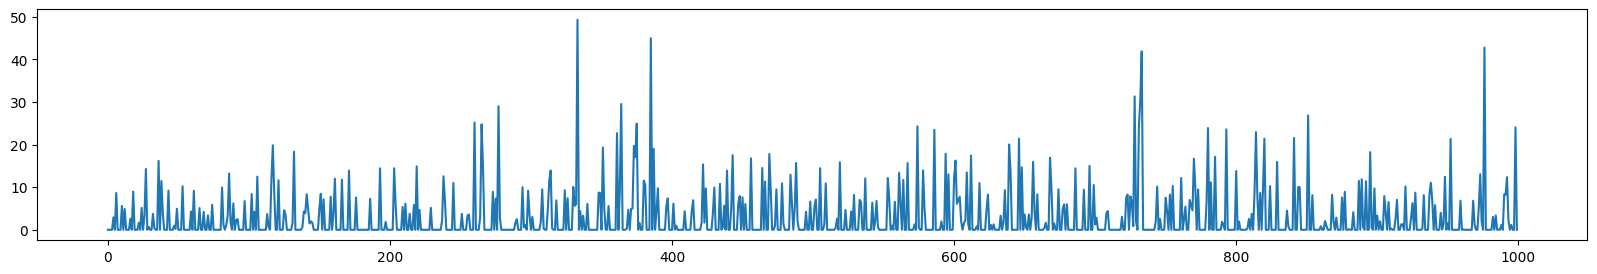

In [6]:
plt.figure(figsize=(20, 3))
plt.plot(traces.values[:1000, 0])

print(np.median(traces))

In [7]:
# preprocess
def reconstruct_calcium(spikes, fs, decay=2.0):
	dt = 1.0 / fs
	gamma = np.exp(-dt / decay)
	trace = np.zeros(spikes.shape, dtype=np.float32)
	for t in range(1, spikes.shape[0]):
		trace[t, :] = gamma * trace[t - 1, :] + spikes[t, :]
	return trace

sampling_rate = read_utils.get_sampling_rate(os.path.join(path, filename))
traces_reconvolved = pd.DataFrame(reconstruct_calcium(traces.values, fs=sampling_rate), columns=traces.columns)

67.659325


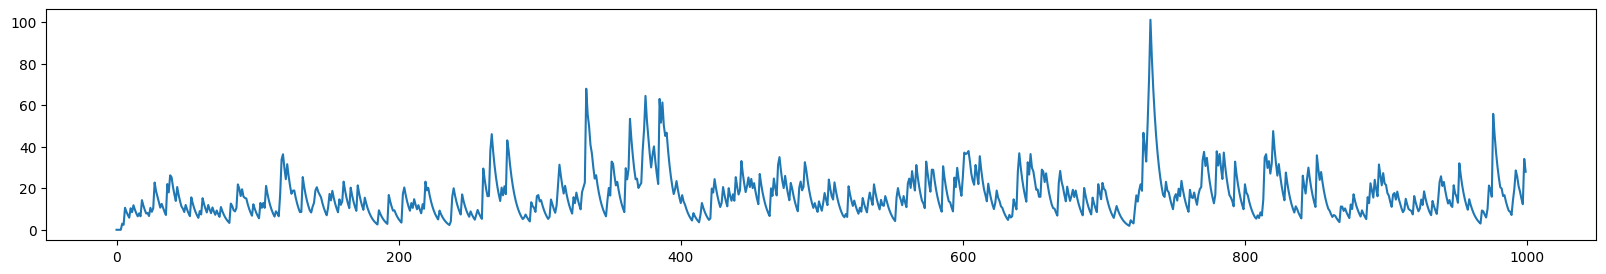

In [8]:
plt.figure(figsize=(20, 3))
plt.plot(traces_reconvolved.values[:1000, 0])

print(np.median(traces_reconvolved.values))

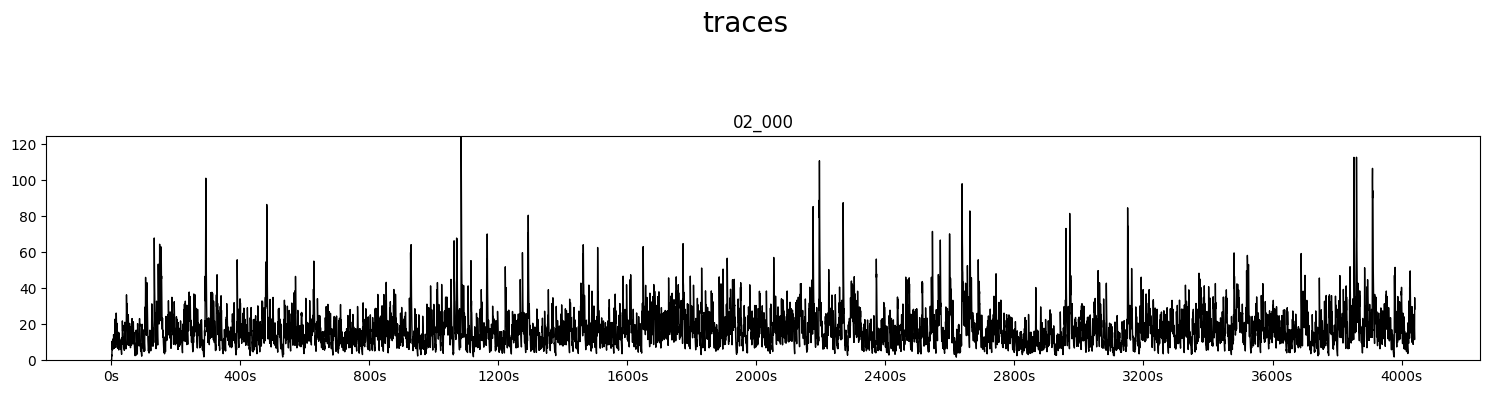

In [9]:
plot_utils.plot_traces(traces_reconvolved.iloc[:, 0:1],
					   None,
					   timestamps)